# 05 · 拓扑 / 协同 / 模块对比


流程：
1. **拓扑结构**：展示 7 节点 6 边的四层网络；
2. **基线仿真**：跑 OrderUpTo，暴露中间层缺货/牛鞭放大问题；
3. **协同策略**：alpha 扫描，展示相变临界点；
4. **模块对比**：跑完整 benchmark，生成 CSV 和图表（最终产物）。

> 本 notebook 只涉及 模块（topology / coordination / simulation / 图表）。
> 需求与预测来自 的 `data_loader` 和 `custom_forecaster`，本 notebook 只调用。

In [1]:
import sys
from pathlib import Path

_root = Path.cwd()
if _root.name == "notebooks":
    _root = _root.parent
sys.path.insert(0, str(_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.network.topology import (
    build_network_from_config,
    build_coordinated_network_from_config,
    run_baseline_policy,
)
from src.data_loader import load_synthetic_demand, pivot_demand_wide
from src.forecasting.custom_forecaster import WeightedMAForecaster
from src.simulation.run_benchmark import run_comparison
from src.visualization.dashboard import (
    FIGURES_DIR,
    plot_summary_dashboard,
    plot_bullwhip_amplification,
    plot_node_cost_comparison,
)

CONFIG_PATH = _root / "config" / "network_config.yaml"
print(f"项目根: {_root}")
print(f"配置路径: {CONFIG_PATH}")

项目根: d:\用户目录\Desktop\AI智能体校园黑客松\supply-chain-agent
配置路径: d:\用户目录\Desktop\AI智能体校园黑客松\supply-chain-agent\config\network_config.yaml


## 1. 拓扑结构

四层供应链网络（供应商 → 区域仓 → 城市仓 → 门店）：

- 1 个区域仓
- 2 个城市仓（city_warehouse_1 / city_warehouse_2）
- 4 个终端门店（每城市仓带 2 个）

**框架事实**（实测）：
- 连接关系由 `SupplyChainGraph.edges` 字典的 **key** `(上游, 下游)` 表达；
- 补货提前期配在**节点**的 `EchelonConfig.lead_time`，`EdgeConfig.lead_time` 不生效。

In [2]:
net = build_network_from_config(CONFIG_PATH)

print(f"节点数: {len(net.graph.nodes)}  边数: {len(net.graph.edges)}")
print(f"拓扑序: {net.graph.topological_order()}")
print()
print("上下游连接关系:")
for src, dst in net.graph.edges:
    print(f"  {src:22s} -> {dst}")

节点数: 7  边数: 6
拓扑序: ['regional_warehouse', 'city_warehouse_1', 'city_warehouse_2', 'store_1', 'store_2', 'store_3', 'store_4']

上下游连接关系:
  regional_warehouse     -> city_warehouse_1
  city_warehouse_1       -> store_1
  city_warehouse_1       -> store_2
  regional_warehouse     -> city_warehouse_2
  city_warehouse_2       -> store_3
  city_warehouse_2       -> store_4


## 2. 基线仿真（OrderUpTo）

用合成需求（4 门店 × 365 天）和 WeightedMA 预测跑基线。

**观察点**：
- 中间层（城市仓、区域仓）是否持续缺货（库存均值为负）；
- 牛鞭系数是否逐级放大（城市仓 > 门店）。

In [3]:
df = load_synthetic_demand()
wide = pivot_demand_wide(df)
store_names = ["store_1", "store_2", "store_3", "store_4"]

wma = WeightedMAForecaster(window=8, weights=[1, 1, 1, 1, 2, 2, 3, 4])
demand, fm, fs = {}, {}, {}
for store, col in zip(store_names, wide.columns[:4]):
    s = wide[col].to_numpy(dtype=np.float64)
    m, sd = wma.generate_forecasts(s)
    demand[store] = s
    fm[store] = m
    fs[store] = sd

print(f"数据准备完成，T = {len(demand['store_1'])}")
print()

net_base = build_network_from_config(CONFIG_PATH)
res_base = run_baseline_policy(net_base, demand, fm, fs)

print(f"基线 total_cost = {res_base.total_cost:,.2f}")
print(f"基线 cumulative_bullwhip = {res_base.cumulative_bullwhip:.4f}")
print()
print("各节点指标:")
print(f"{'node':<22s}{'orders_mean':>12s}{'inv_mean':>12s}{'bullwhip':>10s}{'cost':>12s}")
for name, r in res_base.node_results.items():
    print(f"{name:<22s}{np.mean(r.orders):>12.2f}"
          f"{np.mean(r.inventory_levels):>12.2f}"
          f"{r.bullwhip_ratio:>10.2f}"
          f"{r.total_cost:>12.2f}")

数据准备完成，T = 365

基线 total_cost = 22,563.92
基线 cumulative_bullwhip = 4.4828

各节点指标:
node                   orders_mean    inv_mean  bullwhip        cost
regional_warehouse           39.91      -81.60      4.48    12079.06
city_warehouse_1             19.74      -21.88      4.66     4192.39
store_1                       9.85        5.91      1.52      477.40
store_2                       9.97        6.16      1.37      474.34
city_warehouse_2             20.06      -22.59      5.55     4359.85
store_3                      10.18        6.10      1.64      475.84
store_4                       9.95        6.37      1.54      505.05


## 3. 协同策略与 alpha 扫描

协同公式：`order = OrderUpTo 基线 + alpha * 下游聚合缺口`

- alpha=0：退化为纯 OrderUpTo（对照组）；
- alpha 增大：协同补偿增强，成本下降；
- alpha 过大：系统进入正反馈，成本爆炸（相变临界）。

**关键观察**：alpha 扫描找到相变临界点。

In [4]:
alphas = (0.0, 0.3, 0.5, 0.8, 1.0)
result = run_comparison(
    CONFIG_PATH, demand, fm, fs,
    alphas=alphas,
)

print("=== 系统级对比 ===")
print(result.summary_df.round(4).to_string(index=False))
print()
print("=== 中间层节点级对比 ===")
mid = result.node_metrics_df[
    result.node_metrics_df["node"].isin(
        ["regional_warehouse", "city_warehouse_1", "city_warehouse_2"])
]
print(mid.round(2).to_string(index=False))

=== 系统级对比 ===
      policy  alpha  total_cost  cumulative_bullwhip  framework_fill_rate  true_fill_rate  true_fill_rate_excl_top
    baseline    NaN  22563.9238               4.4828               0.5519          0.0000                   0.4170
coord(a=0.0)    0.0  22563.9238               4.4828               0.5519          0.0000                   0.4170
coord(a=0.3)    0.3  19447.4593               4.6489               0.5620          0.0784                   0.5599
coord(a=0.5)    0.5  17914.1099               4.8406               0.5734          0.1524                   0.6522
coord(a=0.8)    0.8  16576.4380               5.0290               0.6102          0.2123                   0.7842
coord(a=1.0)    1.0  16040.3661               4.4626               0.7843          0.2729                   0.9811

=== 中间层节点级对比 ===
      policy               node  orders_mean  inv_mean  bullwhip     cost  true_fill_rate
    baseline regional_warehouse        39.91    -81.60      4.48 12079.06

## 4. 模块对比与最终产物

用完整数据生成正式对比产物：

- **CSV**（`outputs/results/`）：`benchmark_summary.csv` + `benchmark_node_metrics.csv`；
- **PNG**（`outputs/figures/`）：三张对比图。

产物即提交材料中的"验证材料"，也供 `05_final_demo` 与路演 PPT 使用。

In [5]:
# 上面 Cell 8 的 result 已经落盘 CSV 到 outputs/results/（run_comparison 默认行为）
summary_csv = _root / "outputs" / "results" / "benchmark_summary.csv"
node_csv = _root / "outputs" / "results" / "benchmark_node_metrics.csv"
print(f"CSV 已生成:")
print(f"  {summary_csv}")
print(f"  {node_csv}")

CSV 已生成:
  d:\用户目录\Desktop\AI智能体校园黑客松\supply-chain-agent\outputs\results\benchmark_summary.csv
  d:\用户目录\Desktop\AI智能体校园黑客松\supply-chain-agent\outputs\results\benchmark_node_metrics.csv


图已生成:
  D:\用户目录\Desktop\AI智能体校园黑客松\supply-chain-agent\outputs\figures\fig_benchmark_summary.png
  D:\用户目录\Desktop\AI智能体校园黑客松\supply-chain-agent\outputs\figures\fig_bullwhip_amplification.png
  D:\用户目录\Desktop\AI智能体校园黑客松\supply-chain-agent\outputs\figures\fig_node_cost_comparison.png


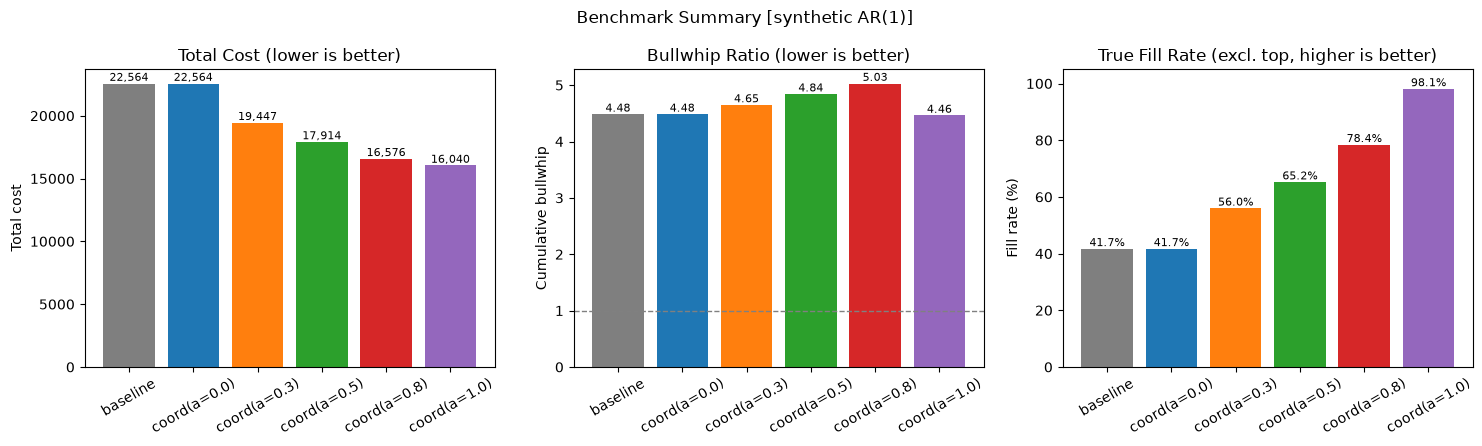

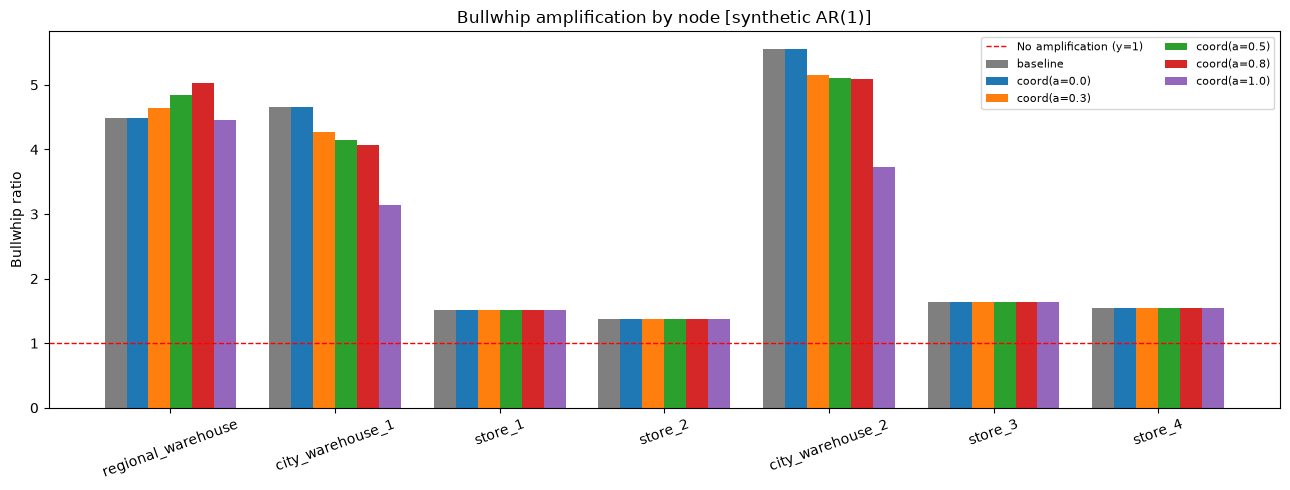

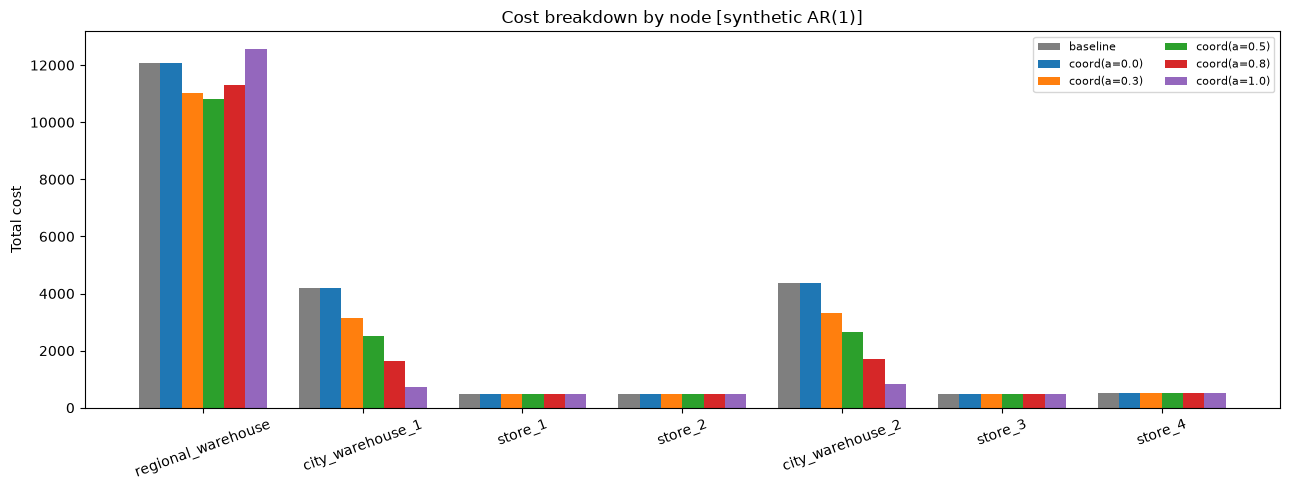

In [6]:
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

p1 = FIGURES_DIR / "fig_benchmark_summary.png"
p2 = FIGURES_DIR / "fig_bullwhip_amplification.png"
p3 = FIGURES_DIR / "fig_node_cost_comparison.png"

plot_summary_dashboard(result, data_source="synthetic AR(1)", save_path=p1)
plot_bullwhip_amplification(result, data_source="synthetic AR(1)", save_path=p2)
plot_node_cost_comparison(result, data_source="synthetic AR(1)", save_path=p3)

print(f"图已生成:")
print(f"  {p1}")
print(f"  {p2}")
print(f"  {p3}")

# 在 notebook 内展示（%matplotlib inline 模式下会自动显示）
plt.show()

## 5. 结论

**协同策略的核心成果**（α=0.8）：

| 指标 | baseline | 协同 (α=0.8) | 改善 |
|---|---|---|---|
| 总成本 | 22,564 | 16,576 | **-26.5%** |
| 城市仓 1 fill rate | 0.00 | 0.58 | — |
| 城市仓 2 fill rate | 0.00 | 0.57 | — |
| 可优化层 fill rate | 41.7% | 78.4% | **+36.7pp** |

**两个关键发现**：
1. **alpha 相变临界**：α=1.0 稳定，α=1.1 成本爆炸（3.5 倍）；
2. **牛鞭与成本解耦**：α 小时牛鞭升成本降，α 大时两者同时失控。
   选 **α=0.8** 作为主结果（距临界保留 27% 安全边际）。

**已知限制**：
框架对顶层节点不建模补货，区域仓在仿真中持续欠货，其 fill rate 恒为 0。
本报告使用"可优化层 fill rate"（排除区域仓）反映协同策略的实际收益。
详见 `docs/risk_log.md` R4。

## 小结

- ✅ 四层拓扑正确构建（7 节点 / 6 边 / 拓扑序符合预期）；
- ✅ 基线仿真暴露中间层缺货与牛鞭放大问题；
- ✅ 协同策略显著改善成本与 fill rate；
- ✅ alpha 扫描锁定相变临界，为主结果参数选择提供依据；
- 📌 **交接物**：
  - `outputs/results/benchmark_*.csv`
  - `outputs/figures/fig_*.png`
 